<a href="https://colab.research.google.com/github/scottaudrey/svd-food-recommendation-system/blob/main/notebooks/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part A: Load your project functions and data**

In [1]:
import os
import subprocess
import sys

USER = "scottaudrey"
REPO = "svd-food-recommendation-system"

if os.path.exists(REPO):
  subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
  subprocess.run(
    ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
    check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

This code connects to my GitHub repository and imports the reusable functions from Milestone 2. These functions will be used to split the ratings, create the rating matrix, calculate RMSE, and build the baseline model.

In [2]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://github.com/ryannewhouse11/FoodReviewData/releases/latest/download/recipereview.zip"
urllib.request.urlretrieve(url, "/content/recipereview.zip")

if not os.path.exists("/content/recipereview.zip"):
  urllib.request.urlretrieve(url, "/content/recipereview.zip")


with zipfile.ZipFile("/content/recipereview.zip", "r") as z:
  csv_files = [
      name for name in z.namelist()
      if name.lower().endswith(".csv") and not name.startswith("_MACOSX/")
  ]

  with z.open(csv_files[0]) as f:
    ratings = pd.read_csv(
        f,
        sep=",",
        header=0,
        names=["num_records", "recipe_number", "recipe_code", "recipe_name",
               "comment_id", "user_id", "user_name", "user_reputation", "created_at",
               "reply_count", "thumbs_up", "thumbs_down", "stars", "best_score", "text"]
    )

ratings = ratings[ratings["stars"].between(1, 5)].copy()

ratings = ratings.groupby(
  ["user_id", "recipe_code"], as_index=False
).agg(
  stars=("stars", "mean"),
  recipe_name=("recipe_name", "first")
)

# This part is added to factor data and make these ID into consecutive integers
# This will help with Part B
# Code from chatgpt
ratings["user_id"] = pd.factorize(ratings["user_id"])[0] + 1
ratings["recipe_code"] = pd.factorize(ratings["recipe_code"])[0] + 1

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

fit: 14878 validation: 435 test: 482


This code loads the recipe reviews and keeps ratings from 1 to 5 stars. It averages repeated ratings from the same user for the same recipe, then converts user and recipe IDs into consecutive numbers. Finally, it splits the data into fitting, validation, and test sets. The models learn from the fitting set, settings are chosen using validation data, and the test set is used for the final comparison.

# **Part B: Set up a fair validation comparison**

In [3]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)

val_truth = val["stars"].to_numpy()
val_u = val["user_id"].to_numpy() - 1
val_i = val["recipe_code"].to_numpy() - 1

def score_at(P, rows, cols, truth):
  """RMSE for selected entries of a prediction matrix."""
  pred = np.clip(P[rows, cols], 1, 5)
  return rmse(pred, truth)

This code creates a user-by-recipe rating matrix using only the fitting data. Missing ratings are represented by NaN. The validation ratings are kept separate to test how accurately the model predicts unknown ratings. The score_at function calculates RMSE by comparing predicted ratings to actual ratings. A lower RMSE means the predictions are more accurate.

# **Part C: Build the baseline prediction matrix**

In [4]:
def baseline_matrix(R):
  """Full matrix: overall mean plus user and recipe effects."""
  mu, b_user, b_item = bias_baseline(R)
  return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.8784


This code creates a baseline prediction matrix using the overall average rating, user rating differences, and recipe rating differences. It then calculates the validation RMSE to measure how accurately the baseline predicts ratings. This gives us a starting point to compare with the SVD models.

# **Part D: Create a rank-k helper**

In [5]:
def rank_k(U, s, Vt, k):
  """Build a rank-k matrix from an already computed SVD."""
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

This code creates a function that uses the first k singular values and their corresponding vectors to reconstruct a lower-rank approximation of the rating matrix. Using a smaller rank helps simplify the matrix while keeping the most important patterns in the ratings.

# **Part E: Model 1 — fill gaps with recipe averages**

In [6]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

This code fills missing ratings with the average rating for each recipe while keeping the known ratings unchanged. It then applies SVD to the completed matrix. This allows the model to estimate missing ratings using patterns in the user-recipe rating data.

# **Part F: Model 2 — let SVD explain what the baseline misses**

In [7]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

This code calculates the difference between known ratings and the baseline predictions. Missing differences are filled with zero, and SVD is applied to the resulting matrix. The goal is to find patterns that the baseline model did not already explain.

# **Part G: Choose rank using validation RMSE**

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
  P1 = rank_k(U1, s1, Vt1, k)
  P2 = rank_k(U2, s2, Vt2, k) + B_fit
  val_err1.append(score_at(P1, val_u, val_i, val_truth))
  val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:", best_k1, "  Validation RMSE:", min(val_err1))
print("Best Model 2 k:", best_k2, " Validation RMSE:", min(val_err2))

Best Model 1 k: 1   Validation RMSE: 0.6627667112976425
Best Model 2 k: 30  Validation RMSE: 0.877437650700559


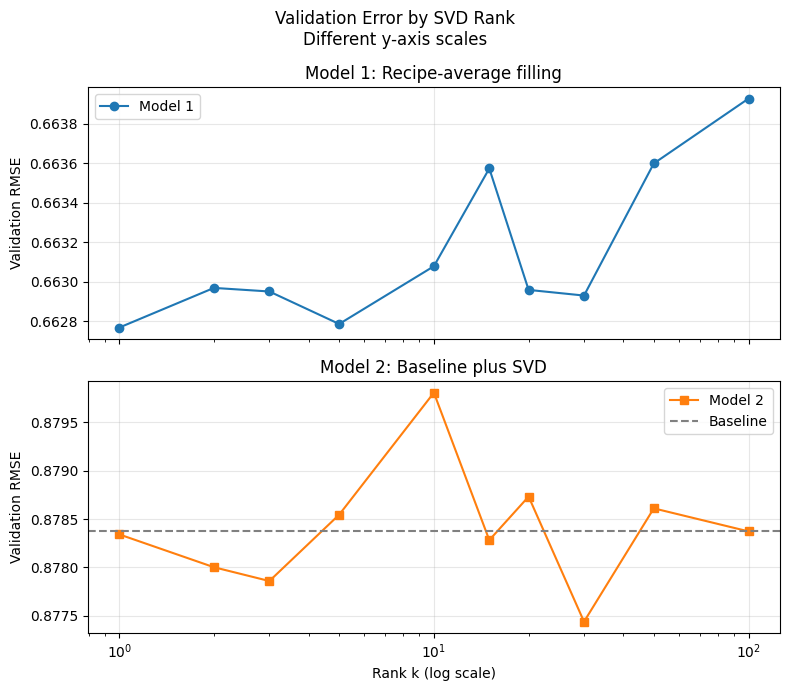

In [17]:
from pathlib import Path
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].semilogx(ks, val_err1, "o-", label="Model 1")
axes[0].set_title("Model 1: Recipe-average filling")
axes[0].set_ylabel("Validation RMSE")

axes[1].semilogx(
  ks, val_err2, "s-", color="tab:orange", label="Model 2"
)
axes[1].axhline(
  baseline_val_rmse, color="gray",
  linestyle="--", label="Baseline"
)
axes[1].set_title("Model 2: Baseline plus SVD")
axes[1].set_ylabel("Validation RMSE")
axes[1].set_xlabel("Rank k (log scale)")

for ax in axes:
  ax.grid(alpha=0.3)
  ax.legend()
  ax.ticklabel_format(axis="y", style="plain", useOffset=False)

fig.suptitle("Validation Error by SVD Rank\nDifferent y-axis scales")
fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/validation_rmse_vs_k.png", dpi=200)
plt.show()

This code tests different rank values for Models 1 and 2 and calculates their validation RMSE. It selects the rank with the lowest error for each model and creates a graph comparing their performance with the baseline. A lower RMSE means the model makes more accurate predictions.

# **Part H: Model 3 — iteratively improve the missing-value guesses**

In [10]:
def iterative_svd_predict(R, k, n_iter=10):
  """Predict ratings by repeatedly"""
  known = ~np.isnan(R)
  B = baseline_matrix(R)
  X = np.where(known, R - B, 0.0)

  for _ in range(n_iter):
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    L = rank_k(U, s, Vt, k)
    X = np.where(known, R - B, L)

  return L + B

In [11]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
  P3 = iterative_svd_predict(R_fit, k, n_iter=10)
  val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.8738040455518443


This code creates an iterative SVD model that repeatedly updates the estimates for missing ratings while keeping the known rating differences unchanged. It tests several ranks and compares their validation RMSE values to determine which rank produces the most accurate predictions.

# **Part I: Refit and evalute on the test set once**

In [12]:
R_train = to_matrix(train)
test_truth = test["stars"].to_numpy()
test_u = test["user_id"].to_numpy() - 1
test_i = test["recipe_code"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
  test_prediction = iterative_svd_predict(
    R_train, best_k3, n_iter=10)
  chosen_model = """iterative SVD"""
elif min(val_err2) < min(val_err1):
  known_train = ~np.isnan(R_train)
  X_train = np.where(known_train, R_train - B_train, 0.0)
  U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
  test_prediction = rank_k(U, s, Vt, best_k2) + B_train
  chosen_model = "baseline plus low-rank deviations"
else:
  known_train = ~np.isnan(R_train)
  mu_train = np.nanmean(R_train)
  n_item_train = known_train.sum(axis=0)
  means_train = np.full(R_train.shape[1], mu_train)
  has_train = n_item_train > 0
  means_train[has_train] = (
    np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
  F_train = np.where(known_train, R_train, means_train[None, :])
  U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
  test_prediction = rank_k(U, s, Vt, best_k1)
  chosen_model = """SVD of recipe-reveiw-average-filled matrix"""

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: SVD of recipe-reveiw-average-filled matrix
Baseline test RMSE: 0.7474
Chosen model test RMSE: 0.6501


This code selects the SVD model with the lowest validation RMSE and rebuilds it using the full training dataset. It then evaluates the model using the test ratings that were kept separate during training. The test RMSE measures how accurately the chosen model predicts ratings it has not seen before.

# **Part J: Make a few recommendations**

In [13]:
item_info = ratings[
    ["recipe_code", "recipe_name"]
].drop_duplicates(subset=["recipe_code"])
item_info.columns = ["recipe_code", "recipe_name"]

user_id = 1
user_row = user_id - 1

unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
  title = item_info.loc[item_info["recipe_code"] == col + 1, "recipe_name"].iloc[0]

  print(title, "predicted rating:", round(predicted_scores[col], 2))

Homemade Peanut Butter Cups predicted rating: 4.95
Banana Bars with Cream Cheese Frosting predicted rating: 4.94
Flavorful Chicken Fajitas predicted rating: 4.92
Baked Mushroom Chicken predicted rating: 4.91
Vegetarian Linguine predicted rating: 4.89


In [14]:
# NOTE: this shows the rating distribution for the file
# The reason all 5 recipes have a 5.0 rating is because there is a
# high amount of 5 star ratings in this data set
print("Rating distribution:")
print(ratings["stars"].value_counts().sort_index())

print("\nAverage rating:")
print(ratings["stars"].mean())

print("\nKnown training ratings:")
print(np.sum(~np.isnan(R_train)))

print("\nTotal matrix entries:")
print(R_train.size)

Rating distribution:
stars
1.0      276
2.0      227
3.0      471
3.5        1
4.0     1596
4.5        2
5.0    13222
Name: count, dtype: int64

Average rating:
4.726147515036404

Known training ratings:
15313

Total matrix entries:
1242000


This code uses the chosen SVD model to recommend five recipes that a selected user has not rated in the training data. It identifies the recipes with the highest predicted ratings and displays their names and scores. These predictions estimate how much the user might like each recipe, but they do not guarantee that the user will enjoy them.

  # Practice Exercises

## 1. Does filling matter?

In [15]:
exercise_ranks = [1, 5, 20]
fill_results = []

for name, fill in [
  ("Recipe average", item_mean[None, :]),
  ("Overall average", mu_fit),
  ("3 stars", 3.0)
]:
  filled = np.where(known_fit, R_fit, fill)
  U, s, Vt = np.linalg.svd(filled, full_matrices=False)

  for k in exercise_ranks:
    prediction = rank_k(U, s, Vt, k)
    error = score_at(prediction, val_u, val_i, val_truth)
    fill_results.append({
      "Fill method": name,
      "Rank": k,
      "Validation RMSE": error
    })

fill_comparison = pd.DataFrame(fill_results)
print(fill_comparison.to_string(index=False))

    Fill method  Rank  Validation RMSE
 Recipe average     1         0.662767
 Recipe average     5         0.662785
 Recipe average    20         0.662958
Overall average     1         0.670938
Overall average     5         0.670963
Overall average    20         0.671349
        3 stars     1         1.775821
        3 stars     5         1.793410
        3 stars    20         1.810287


Filling with recipe averages worked best, with an RMSE of 0.663. The overall average was 0.671. Filling with 3 stars was much worse because most ratings are higher than 3. Filling with 0 would also be a bad choice because a missing rating does not mean the user disliked the recipe.

## 2. Understand the full-rank check.

At full rank, Model 2 accurately reconstructs the residual matrix. Missing entiries were filled with 0, so adding the baseline back gives the baseline prediction at those entries.

## 3. Study iteration.

In [16]:
for rounds in [1, 2, 5, 10]:
  prediction = iterative_svd_predict(
    R_fit, k=5, n_iter=rounds
  )
  error = score_at(prediction, val_u, val_i, val_truth)
  print(f"Rounds: {rounds}, validation RMSE: {error:.6f}")

Rounds: 1, validation RMSE: 0.878545
Rounds: 2, validation RMSE: 0.879648
Rounds: 5, validation RMSE: 0.884209
Rounds: 10, validation RMSE: 0.890511


More iterations did not help here. With rank 5, validation RMSE increased from around 0.879 to 0.891 from 1 to 10 rounds. 1 round worked the best out of the options.

## 4. Check for overfitting.

Model 1's validation RMSE stayed close to 0.663 across the ranks tested, so those results showed little change with rank. The selected model's final test RMSE was 0.6501, which was slightly lower. We must choose the rank using validation data before checking the test score, or we'd be tuning the model to the test set instead of using it as an honest final check.

## 5. Cold-start limitation.

For a new user with no ratings, the model cannot learn their personal tastes. It can fall back on recipe averages or popular recipes. Asking them to rate a few recipes or share preferences could help make initial recommendations more personal.

## 6. Explain the result.

The baseline's test RMSE was 0.7474, while the chosen SVD model scored 0.6501, so the SVD model predicted the test ratings more accurately. The recommendations list recipes that the user has not rated in the training data, ordered by predicted rating. These predictions do not gurantee the user will enjoy said recipes.